# T02 — Order types and matching

*How do the order types of OMIE behave?*

**What you will learn**

- what happens to the unfilled part of a limit, an immediate-or-cancel and a fill-or-kill order;
- how an iceberg order hides most of its quantity, and why its new peak waits at the back of the queue;
- how an iceberg with a price increment moves its price after each peak;
- what the validity conditions mean, and why a modified order loses its place in the queue;
- why an order is rejected.

**What you need**

- Previous tutorials: [T01 — Your first contract](T01_first_contract.ipynb) (linked, not required).
- Run time: under 1 minute on a central processing unit (CPU). Most of it is the first call, which compiles the matching code.
- Network: no.

## Setup

Imports, the device (CPU by default), the seeds, the figure style and the repository root.
Every data path is built from `ROOT`, never relative to this folder.

In [1]:
# Setup: device, repository root, seeds and the figure style. Run this cell first.
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # CPU by default; export JAX_PLATFORMS=cuda before Jupyter for a GPU

# The repository root is the first folder above this notebook that holds pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_DIR = ROOT / "data" / "rawOMIE"  # every data path starts here (ignored by git), never under tutorials/

import jax
import matplotlib.pyplot as plt
import numpy as np

SEED = 0  # fixed seeds: a re-run gives the same market results
rng = np.random.default_rng(SEED)
key = jax.random.PRNGKey(SEED)

# Figure style, the same five lines in every tutorial: buy, sell, a third series, neutral.
BUY, SELL, THIRD, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "legend.frameon": False, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print(f"JAX {jax.__version__}, backend: {jax.default_backend()}")

JAX 0.6.2, backend: cpu


## 1. One contract and a few helpers

OMIE (Operador del Mercado Ibérico de Energía) runs the continuous intraday market (CID) of Spain and
Portugal. As in [T01](T01_first_contract.ipynb), we trade contract 52: power delivered from 13:00 to
13:15, with gate closure at 12:00. Prices are in euros per megawatt-hour (EUR/MWh) and quantities in
megawatts (MW).

The package has no public helper to open a contract, so we make an open copy with
`dataclasses.replace`. At book level, the caller gives each order an identifier and a timestamp.
The helper `submit` keeps both counters: orders arrive 5 seconds apart from 10:00:00, and a timestamp
is the number of seconds after midnight of the delivery day. `show_book` prints the anonymous book.

In [2]:
import dataclasses

from omiecid_simulator.omiecid.contract import ContractStatus, generate_contracts
from omiecid_simulator.omiecid.contract_book import ContractBook
from omiecid_simulator.omiecid.order_types import ExecRestriction, Side, Validity, make_order

contract = dataclasses.replace(generate_contracts()[52], status=ContractStatus.OPEN)  # no public "open" helper
book = ContractBook(contract)
empty = book.init()
counter = {"order_id": 0, "time": 10 * 3600}  # first order at 10:00:00


def submit(state, side, price, qty, agent_id=1, **kwargs):
    # Give the order the next id and a timestamp 5 s after the previous one, then submit it.
    counter["order_id"] += 1
    counter["time"] += 5
    order = make_order(contract.contract_id, side, float(price), float(qty), counter["order_id"],
                       agent_id, counter["time"], **kwargs)
    state, result = book.submit_order(state, order)
    return state, result, order.order_id


def clock(seconds):
    # Seconds after midnight as a clock time.
    return f"{seconds // 3600:02d}:{seconds // 60 % 60:02d}:{seconds % 60:02d}"


def show_book(state, label):
    bids, asks = book.get_anonymous_lob(state)
    levels = [f"ask {p:.2f}: {q:.1f} MW" for p, q in sorted(asks, reverse=True)]
    levels += [f"bid {p:.2f}: {q:.1f} MW" for p, q in bids]
    print(f"{label:<14} " + (" | ".join(levels) or "empty"))

## 2. Limit, immediate-or-cancel and fill-or-kill

Two sellers offer 6 MW in total: 2 MW at 52.00 EUR/MWh and 4 MW at 52.50 EUR/MWh. A buyer wants 10 MW
and will pay up to 53.00 EUR/MWh. Only 6 MW are on offer, so the question is what happens to the
other 4 MW. The **execution restriction** of the order decides.

> **Concept — limit order (NON).** A plain limit order has no restriction (OMIE writes "NON"). It
> trades what it can at its limit price or better. The rest **rests** in the book with the timestamp the
> order arrived with (a partial fill does not change it), until it trades, is cancelled, or the
> contract closes.

> **Concept — immediate-or-cancel (IOC).** An IOC order trades what it can at once. The unfilled
> part is cancelled; nothing rests.

> **Concept — fill-or-kill (FOK).** A FOK order trades only if it can be filled completely at once.
> Otherwise the whole order is cancelled and nothing trades.

The book is a value: each call returns a new state. So we can send the same buy, with each
restriction, to the same starting book `base`.

In [3]:
base, _, _ = submit(empty, Side.SELL, 52.00, 2)
base, _, _ = submit(base, Side.SELL, 52.50, 4, agent_id=3)
show_book(base, "before")

outcomes = {}  # restriction -> (traded, rests in the book, cancelled), in MW
for restriction in (ExecRestriction.NON, ExecRestriction.IOC, ExecRestriction.FOK):
    after, result, oid = submit(base, Side.BUY, 53.00, 10, agent_id=2, exec_restriction=restriction)
    resting = book.get_order(after, oid, Side.BUY)  # a sentinel order with another id if not resting
    rests = resting.quantity if resting.order_id == oid else 0.0
    traded = float(result.trade_qty)
    cancelled = round(10 - traded - rests, 1)
    outcomes[restriction.name] = (traded, rests, cancelled)
    print(f"{restriction.name}: accepted {bool(result.accepted)}, traded {traded:.1f} MW, "
          f"rests {rests:.1f} MW, cancelled {cancelled:.1f} MW")
    show_book(after, "   book after")

before         ask 52.50: 4.0 MW | ask 52.00: 2.0 MW
NON: accepted True, traded 6.0 MW, rests 4.0 MW, cancelled 0.0 MW
   book after  bid 53.00: 4.0 MW
IOC: accepted True, traded 6.0 MW, rests 0.0 MW, cancelled 4.0 MW
   book after  empty
FOK: accepted True, traded 0.0 MW, rests 0.0 MW, cancelled 10.0 MW
   book after  ask 52.50: 4.0 MW | ask 52.00: 2.0 MW


The limit order and the IOC both buy the 6 MW on offer. The limit order then waits in the book as a
4 MW bid at 53.00 EUR/MWh; the IOC drops its 4 MW. The FOK cannot get all 10 MW, so it trades nothing
and the asks stay where they were. Note that an order with an unfilled part is still **accepted**:
being cancelled by its own restriction is not a rejection.

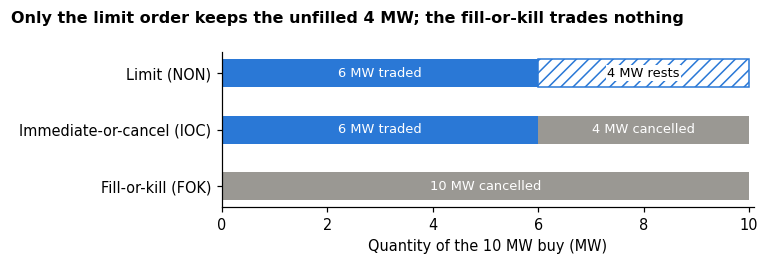

In [4]:
labels = {"NON": "Limit (NON)", "IOC": "Immediate-or-cancel (IOC)", "FOK": "Fill-or-kill (FOK)"}
filled, rests, cancelled = (np.array(v) for v in zip(*outcomes.values()))
y = np.arange(len(outcomes))[::-1]
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.barh(y, filled, color=BUY, height=0.5)
ax.barh(y, rests, left=filled, color="white", edgecolor=BUY, hatch="///", height=0.5)
ax.barh(y, cancelled, left=filled + rests, color=GREY, height=0.5)
for yi, f, r, c in zip(y, filled, rests, cancelled):
    for left, w, txt in ((0, f, "traded"), (f, r, "rests"), (f + r, c, "cancelled")):
        if w:
            ax.text(left + w / 2, yi, f"{w:g} MW {txt}", ha="center", va="center", fontsize=8.5,
                    color="black" if txt == "rests" else "white",
                    bbox=dict(facecolor="white", edgecolor="none", pad=1) if txt == "rests" else None)
ax.set_yticks(y, [labels[k] for k in outcomes]); ax.set_xlabel("Quantity of the 10 MW buy (MW)")
ax.set_xlim(0, 10.1); ax.grid(False)
fig.suptitle("Only the limit order keeps the unfilled 4 MW; the fill-or-kill trades nothing",
             x=0.01, ha="left", fontsize=10.5, fontweight="bold")
fig.tight_layout()
plt.show()

## 3. Iceberg orders: the new peak joins the back of the queue

A participant may not want to show the full size of a large order. An **iceberg** shows only a
small part of it.

> **Concept — iceberg order (ICE).** An iceberg has a total quantity and a **peak**: the part shown
> in the book. The rest is hidden. When the peak is fully traded, a new peak of the same size (or the
> remainder, if smaller) is shown at once, inside the same matching process, with a new timestamp.
> A new timestamp means a new place in the queue: the new peak goes **behind** every order already
> waiting at that price.

An iceberg always rests like a limit order; it cannot be IOC or FOK.

At 52.00 EUR/MWh three sellers queue in time order: A (participant 3) sells 3 MW, then B (participant 4)
sends an iceberg of 10 MW with a 2 MW peak, then C (participant 5) sells 4 MW. Other participants see 3 + 2 + 4 = 9 MW at that price. B, the owner,
sees its full 10 MW (`get_agent_orders`).

The package has no call that lists the queue at one price level, order by order. The helper `queue`
builds it: `get_order` gives the shown quantity, the participant and the timestamp of one order, and
the owner's view of that participant adds the hidden part. Then the orders are sorted by timestamp.

In [5]:
def queue(state, names, side=Side.SELL):
    # The resting orders `names` (order id -> name), front of the queue first: (name, shown, hidden, time).
    rows = []
    for oid, name in names.items():
        shown = book.get_order(state, oid, side)
        if shown.order_id != oid:  # not resting any more
            continue
        total = sum(o.quantity for o in book.get_agent_orders(state, shown.agent_id) if o.order_id == oid)
        rows.append((shown.timestamp, name, shown.quantity, round(total - shown.quantity, 1)))
    return [(name, shown, hidden, clock(ts)) for ts, name, shown, hidden in sorted(rows)]


state, _, a = submit(empty, Side.SELL, 52.00, 3, agent_id=3)
state, _, b = submit(state, Side.SELL, 52.00, 10, agent_id=4, exec_restriction=ExecRestriction.ICE, peak_qty=2.0)
state, _, c = submit(state, Side.SELL, 52.00, 4, agent_id=5)
names = {a: "A", b: "B", c: "C"}
queue_before = queue(state, names)
show_book(state, "public book")
for name, shown, hidden, t in queue_before:
    print(f"   {name}: shown {shown:.1f} MW, hidden {hidden:.1f} MW, in the queue since {t}")

public book    ask 52.00: 9.0 MW
   A: shown 3.0 MW, hidden 0.0 MW, in the queue since 10:00:30
   B: shown 2.0 MW, hidden 8.0 MW, in the queue since 10:00:35
   C: shown 4.0 MW, hidden 0.0 MW, in the queue since 10:00:40


A buyer now takes 5 MW at 52.00 EUR/MWh. Price-time priority serves A first (3 MW), then B's peak
(2 MW). B's peak is used up, so B shows a new 2 MW peak, stamped at the time of the buy. C arrived
earlier, so C is now at the front.

In [6]:
state, result, _ = submit(state, Side.BUY, 52.00, 5, agent_id=2)
print(f"traded {float(result.trade_qty):.1f} MW at {float(result.trade_price):.2f} EUR/MWh")
queue_after = queue(state, names)
show_book(state, "public book")
for name, shown, hidden, t in queue_after:
    print(f"   {name}: shown {shown:.1f} MW, hidden {hidden:.1f} MW, in the queue since {t}")

traded 5.0 MW at 52.00 EUR/MWh
public book    ask 52.00: 6.0 MW
   C: shown 4.0 MW, hidden 0.0 MW, in the queue since 10:00:40
   B: shown 2.0 MW, hidden 6.0 MW, in the queue since 10:00:45


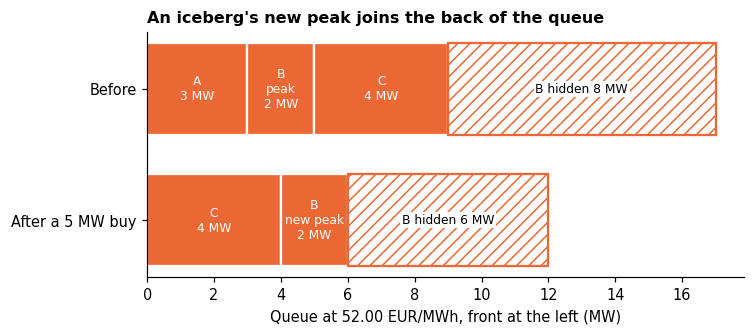

In [7]:
def draw_queue(ax, yv, rows, new_peak=()):
    # One row of segments, front of the queue at the left; the hidden parts go at the end, hatched.
    segments = []
    for name, shown, hidden, _ in rows:
        role = "new peak" if name in new_peak else "peak" if hidden else None
        segments.append(("\n".join(x for x in (name, role, f"{shown:g} MW") if x), shown, False))
    segments += [(f"{name} hidden {hidden:g} MW", hidden, True) for name, _, hidden, _ in rows if hidden]
    left = 0.0
    for label, q, hidden in segments:
        style = dict(color="white", edgecolor=SELL, hatch="///") if hidden else dict(color=SELL, edgecolor="white")
        ax.barh(yv, q, left=left, height=0.7, lw=1.5, **style)
        ax.text(left + q / 2, yv, label, ha="center", va="center", fontsize=8,
                color="black" if hidden else "white",
                bbox=dict(facecolor="white", edgecolor="none", pad=1) if hidden else None)
        left += q


fig, ax = plt.subplots(figsize=(7, 2.9))
draw_queue(ax, 1, queue_before)
draw_queue(ax, 0, queue_after, new_peak=("B",))
ax.set_yticks([1, 0], ["Before", "After a 5 MW buy"]); ax.grid(False)
ax.set_xlabel("Queue at 52.00 EUR/MWh, front at the left (MW)")
ax.set_title("An iceberg's new peak joins the back of the queue")
plt.show()

## 4. Iceberg with a price increment: each new peak moves the price

> **Concept — iceberg with price increment (ICEwPI).** An ICEwPI is an iceberg whose price changes by a
> fixed step, the **price increment** (`ppd`), each time a new peak appears. With base price $b$ and
> increment $d$, peak number $k$ (counted from 0) is priced at $p_k = b + k\,d$. A sell needs $d > 0$,
> so it asks more as it sells; a buy needs $d < 0$, so it bids less as it buys.

A seller offers 6 MW in peaks of 2 MW, from 52.00 EUR/MWh, with $d = +0.50$ EUR/MWh. Its three peaks are
priced 52.00, 52.50 and 53.00. A buyer takes 3 MW at up to 53.00 EUR/MWh: 2 MW from the first peak,
then 1 MW from the second, at its own higher price.

In [8]:
state, _, seller = submit(empty, Side.SELL, 52.00, 6, exec_restriction=ExecRestriction.ICE,
                          peak_qty=2.0, ppd=0.50)
show_book(state, "before")
state, result, _ = submit(state, Side.BUY, 53.00, 3, agent_id=2)
for price, qty, _ in book.get_agent_trades(state, 2):
    print(f"   trade: {qty:.1f} MW at {price:.2f} EUR/MWh")
show_book(state, "after")
left = sum(o.quantity for o in book.get_agent_orders(state, 1) if o.order_id == seller)
bids, asks = book.get_anonymous_lob(state)
print(f"the seller still has {left:.1f} MW in total; the book shows {asks[0][1]:.1f} MW of it at {asks[0][0]:.2f} EUR/MWh")

before         ask 52.00: 2.0 MW
   trade: 2.0 MW at 52.00 EUR/MWh
   trade: 1.0 MW at 52.50 EUR/MWh


after          ask 52.50: 1.0 MW


the seller still has 3.0 MW in total; the book shows 1.0 MW of it at 52.50 EUR/MWh


The seller's last 2 MW peak will be priced at 53.00 EUR/MWh. In both cases the resting iceberg is the
passive side, so every trade prints at the iceberg's own
price. An iceberg that crosses the book when it arrives follows further rules, described in
[the market model](../docs/market-model.md#icebergs).

## 5. Validity: until gate closure, or until a time

> **Concept — validity (GFS and GTD).** Good-for-session (GFS), the default, keeps an order valid until
> the contract's gate closure. Good-till-date (GTD) keeps it valid until a time the sender chooses,
> no later than gate closure.

The book has no clock of its own. In this simulator a GTD order carries its expiry time, but nothing
removes it before gate closure: it rests until it trades, is cancelled, or the contract closes. At
gate closure, `expire_at_gct` cancels every resting order. Below, a GTD bid that should lapse at
10:05:00 is accepted and rests like any other bid.

In [9]:
state, _, _ = submit(empty, Side.SELL, 52.00, 2)
state, result, _ = submit(state, Side.BUY, 50.00, 1, validity=Validity.GTD, expiry_time=10 * 3600 + 300)
print(f"GTD bid accepted: {bool(result.accepted)}")
show_book(state, "before closure")
show_book(book.expire_at_gct(state), "at closure")

GTD bid accepted: True
before closure ask 52.00: 2.0 MW | bid 50.00: 1.0 MW
at closure     empty


## 6. A modified order loses its place

> **Concept — modification.** Changing an order (its price, its quantity or its execution restriction)
> gives it a new timestamp. It is ranked as if it had just arrived, so it loses its time priority. At
> book level you supply that new timestamp yourself, as the code below does.

`modify_order` cancels the old order and submits the new one. Below, X (participant 1) and Y
(participant 3) both sell 3 MW at 52.00 EUR/MWh, X first. X then lowers its quantity to 2 MW. A buyer takes 1 MW: Y, not X, trades.

In [10]:
state, _, x = submit(empty, Side.SELL, 52.00, 3)
state, _, y = submit(state, Side.SELL, 52.00, 3, agent_id=3)
names = {x: "X", y: "Y"}


def line(state):
    return [(n, f"{s:.1f} MW", t) for n, s, _, t in queue(state, names)]


print("before:", line(state))

counter["time"] += 5  # the modified order is stamped with a new, later time; it keeps its id
state, result = book.modify_order(state, x, Side.SELL,
                                  make_order(contract.contract_id, Side.SELL, 52.00, 2.0, x, 1, counter["time"]))
print("after X is modified:", line(state))

state, result, _ = submit(state, Side.BUY, 52.00, 1, agent_id=2)
print("after a 1 MW buy:", line(state))

before: [('X', '3.0 MW', '10:01:10'), ('Y', '3.0 MW', '10:01:15')]


after X is modified: [('Y', '3.0 MW', '10:01:15'), ('X', '2.0 MW', '10:01:20')]
after a 1 MW buy: [('Y', '2.0 MW', '10:01:15'), ('X', '2.0 MW', '10:01:20')]


Modification at book level is not part of the certified scenarios
([modelling assumptions](../docs/modelling-assumptions.md#simplifications)).

## 7. Rejected orders

The book checks every order before it can trade. An order is rejected when:

- the contract is not open;
- its price is outside $[-9{,}999,\ +9{,}999]$ EUR/MWh;
- its quantity is outside $[0.1,\ 999]$ MW;
- it is an iceberg whose peak is zero or less, or larger than its total quantity (a peak equal to
  the total is allowed);
- it is an ICEwPI whose increment has the wrong sign.

Prices and quantities are first rounded to the nearest tick (0.01 EUR/MWh and 0.1 MW). A rejected
order changes nothing in the book. The validator (`validate_order`) returns only "accepted" or
"rejected", without the reason. The helper `broken_rules` below restates the five rules in plain
Python so that we can print the reason, and we check that it agrees with the validator.

In [11]:
from omiecid_simulator.omiecid.encoding import encode_ppd, encode_price, encode_qty
from omiecid_simulator.omiecid.omie_config import OMIEProductConfig
from omiecid_simulator.omiecid.order_validator import validate_order

cfg = OMIEProductConfig()  # the default limits: prices, quantities and ticks


def broken_rules(order, status):
    # The rejection rules of the market model, in ticks after rounding, as the validator applies them
    # (the validator gives no reason).
    p, q = encode_price(order.price, cfg), encode_qty(order.quantity, cfg)
    rules = {"the contract is not open": status != ContractStatus.OPEN,
             "price outside -9,999 to 9,999 EUR/MWh":
                 not encode_price(cfg.price_min, cfg) <= p <= encode_price(cfg.price_max, cfg),
             "quantity outside 0.1 to 999 MW": not encode_qty(cfg.qty_min, cfg) <= q <= encode_qty(cfg.qty_max, cfg)}
    if order.exec_restriction == ExecRestriction.ICE:
        d = encode_ppd(order.ppd, cfg)
        rules["iceberg peak zero or larger than the quantity"] = not 0 < order.peak_qty <= order.quantity
        rules["price increment of the wrong sign"] = d > 0 if order.side == Side.BUY else d < 0
    return [rule for rule, broken in rules.items() if broken]


ICE = dict(exec_restriction=ExecRestriction.ICE)
tests = {"buy at 10,000 EUR/MWh": (Side.BUY, 10000.0, 1.0, {}),
         "sell of 0.04 MW": (Side.SELL, 52.0, 0.04, {}),
         "sell of 0.06 MW (rounds to 0.1)": (Side.SELL, 52.0, 0.06, {}),
         "buy iceberg, peak 5 MW of 3 MW": (Side.BUY, 50.0, 3.0, dict(ICE, peak_qty=5.0)),
         "buy ICEwPI, increment +0.50": (Side.BUY, 50.0, 6.0, dict(ICE, peak_qty=2.0, ppd=0.5))}
for label, (side, price, qty, kwargs) in tests.items():
    _, result, oid = submit(empty, side, price, qty, **kwargs)
    order = make_order(contract.contract_id, side, price, qty, oid, 1, counter["time"], **kwargs)
    reasons = broken_rules(order, contract.status)
    assert bool(validate_order(order, cfg, True)) == bool(result.accepted) == (not reasons)
    print(f"{label:<32} accepted {bool(result.accepted)!s:<5}  reason: {', '.join(reasons) or 'none'}")

closed = dataclasses.replace(contract, status=ContractStatus.CLOSED)
order = make_order(contract.contract_id, Side.BUY, 50.0, 1.0, counter["order_id"] + 1, 1, counter["time"] + 5)
_, result = ContractBook(closed).submit_order(empty, order)
print(f"{'a valid buy after gate closure':<32} accepted {bool(result.accepted)!s:<5}  "
      f"reason: {', '.join(broken_rules(order, closed.status))}")

buy at 10,000 EUR/MWh            accepted False  reason: price outside -9,999 to 9,999 EUR/MWh
sell of 0.04 MW                  accepted False  reason: quantity outside 0.1 to 999 MW
sell of 0.06 MW (rounds to 0.1)  accepted True   reason: none
buy iceberg, peak 5 MW of 3 MW   accepted False  reason: iceberg peak zero or larger than the quantity
buy ICEwPI, increment +0.50      accepted False  reason: price increment of the wrong sign
a valid buy after gate closure   accepted False  reason: the contract is not open


## What is not modelled

Block orders, basket orders and all-or-nothing orders are not modelled. Validity is carried on the
order, but a GTD order lapses only at gate closure. The checks of a participant's guarantee and of
the system operator's limits are not modelled either. See [the market model](../docs/market-model.md)
and [the modelling assumptions](../docs/modelling-assumptions.md).

## Recap

- A limit order (NON) rests its unfilled part, an IOC cancels it, and a FOK trades all or nothing.
- An iceberg (ICE) shows only its peak. Each new peak gets a new timestamp and joins the back of the queue.
- An ICEwPI moves its price by the increment $d$ at each new peak: $p_k = b + k\,d$.
- In this simulator, GFS and GTD orders both rest until they trade, are cancelled, or the contract
  closes (in the real market a GTD order also lapses at its chosen time). A modified order loses its
  place.
- A rejected order changes nothing; `SubmitResult.accepted` is `False`.

## Exercises

1. **A fill-or-kill that fills.** Send a FOK buy of 6 MW at 52.50 EUR/MWh to the book `base` of
   section 2. Does it trade, and at what average price?
   *Hint:* a FOK counts every quantity it can reach within its limit, at every price level.
2. **A larger buy against the iceberg.** Rebuild the queue A, B, C of section 3 and send a buy of
   7 MW instead of 5 MW. Which orders trade, and what is the queue afterwards?
   *Hint:* after A and B's first peak, the next order in the queue is C, not B's new peak.
3. **A buy iceberg with a price increment (optional).** Fix the rejected ICEwPI of section 7 so
   that it is accepted. What does each new peak of a buy ICEwPI do to its price?
   *Hint:* a buyer that keeps buying bids less.

The solutions are in the collapsed cell at the end.

## Further reading

- [The market model](../docs/market-model.md): the order types table, icebergs, validation, partial fills. [The modelling assumptions](../docs/modelling-assumptions.md): the iceberg rulings and what is not modelled.
- [Sessions](../docs/sessions.md): the same order types sent by a participant during a trading session.
- The evidence: [the market specification](../docs/omiecid/market-spec.md) and [the certificate](../docs/omiecid/certificate.md). Scenarios [C01](../notebooks/certification/C01_order_validation.ipynb) (validation), [C07](../notebooks/certification/C07_ioc.ipynb) (IOC), [C08](../notebooks/certification/C08_iceberg_regeneration.ipynb) (iceberg peaks), [C09](../notebooks/certification/C09_icewpi_price_drift.ipynb) (ICEwPI) and [C10](../notebooks/certification/C10_fok_and_hidden_volume.ipynb) (FOK) certify the behaviour shown here.
- Previous tutorial: [T01 — Your first contract](T01_first_contract.ipynb).

## Solutions

In [12]:
# Solutions to the exercises (collapsed; expand to read).
# 1. The 6 MW on offer are all within 52.50 EUR/MWh, so the FOK fills completely.
after, r, _ = submit(base, Side.BUY, 52.50, 6, agent_id=2, exec_restriction=ExecRestriction.FOK)
print(f"1. traded {float(r.trade_qty):.1f} MW at an average of {float(r.trade_price):.2f} EUR/MWh")
show_book(after, "   book after")

# 2. A 7 MW buy takes A (3 MW), B's first peak (2 MW), then 2 MW of C, which is ahead of B's new peak.
s, _, a = submit(empty, Side.SELL, 52.00, 3, agent_id=3)
s, _, b = submit(s, Side.SELL, 52.00, 10, agent_id=4, exec_restriction=ExecRestriction.ICE, peak_qty=2.0)
s, _, c = submit(s, Side.SELL, 52.00, 4, agent_id=5)
s, r, _ = submit(s, Side.BUY, 52.00, 7, agent_id=2)
print("2.", [(n, f"shown {sh:.1f} MW", f"hidden {h:.1f} MW") for n, sh, h, _ in queue(s, {a: "A", b: "B", c: "C"})])

# 3. A buy ICEwPI needs a negative increment: each new peak bids 0.50 EUR/MWh less
#    (peaks at 50.00, 49.50 and 49.00 EUR/MWh).
s, r, _ = submit(empty, Side.BUY, 50.0, 6.0, exec_restriction=ExecRestriction.ICE, peak_qty=2.0, ppd=-0.5)
print(f"3. accepted {bool(r.accepted)}")
show_book(s, "   book")

1. traded 6.0 MW at an average of 52.33 EUR/MWh
   book after  empty


2. [('C', 'shown 2.0 MW', 'hidden 0.0 MW'), ('B', 'shown 2.0 MW', 'hidden 6.0 MW')]
3. accepted True
   book        bid 50.00: 2.0 MW
